# 🕸️ LangGraph 기초부터 차근차근
---
## 🧭 학습 로드맵

| 단계 | # | 주제 | 핵심 키워드 | LLM 필요? |
|:----:|:-:|------|-------------|:---------:|
| 🌱 **기초** | 1 | LangGraph 란? | State · Node · Edge · 슈퍼스텝 | ❌ |
| | 2 | 첫 번째 그래프 | `StateGraph`, `compile`, `invoke` | ❌ |
| | 3 | 노드 여러 개 연결 | 순차 실행, 상태 갱신 규칙 | ❌ |
| | 4 | State 스키마 | `TypedDict` / `dataclass` / `Pydantic`, 입력·출력 스키마 | ❌ |
| | 5 | 리듀서 | `Annotated`, `operator.add`, `add_messages` | ❌ |
| 🌿 **흐름 제어** | 6 | 조건부 엣지 | `add_conditional_edges` | ❌ |
| | 7 | 반복(사이클) | 루프, `recursion_limit` | ❌ |
| | 8 | 병렬 실행 | fan-out / fan-in | ❌ |
| | 9 | `Send` | 개수가 정해지지 않은 병렬(Map-Reduce) | ❌ |
| | 10 | `Command` | 상태 업데이트 + 이동 한 번에 | ❌ |
| | 11 | 런타임 컨텍스트 | `context_schema`, `Runtime` | ❌ |
| 🌳 **LLM 에이전트** | 12 | LLM 노드 · 챗봇 | `MessagesState` | ✅ |
| | 13 | LLM 라우팅 | 구조화된 출력 + 조건부 엣지 | ✅ |
| | 14 | 도구 에이전트 (ReAct) | `ToolNode`, `tools_condition` | ✅ |
| 🌲 **운영 기능** | 15 | 메모리 | 체크포인터, `thread_id` | ✅ |
| | 16 | 스트리밍 | `stream_mode` 5가지 | ✅ |
| | 17 | Human-in-the-loop | `interrupt`, `Command(resume)` | ❌ |
| | 18 | 에러 처리 | `RetryPolicy` | ❌ |
| | 19 | 서브그래프 | 그래프 안의 그래프 | ❌ |
| 🏁 **종합** | 20 | 글쓰기 에이전트 | 루프 + 사람 피드백 + LLM | ✅ |
| | 21 | 정리 | 치트시트 · 연습문제 · 다음 단계 | ❌ |

> **한눈에 보기**
> - 리듀서 `Annotated[타입, 함수]`: 덮어쓰기 대신 합치기 (`operator.add`, `add_messages`, 직접 만든 함수)
> - 조건부 엣지 `add_conditional_edges` (+`Literal`, `path_map`), 앞 노드로 돌아가면 반복, 상한은 `recursion_limit`
> - 병렬 fan-out / fan-in(`add_edge([A, B, C], join)`), 개수가 바뀌는 병렬 `Send`, 갱신 + 이동 `Command`
> - 실행 내내 바뀌지 않는 설정은 `context_schema` + `Runtime`
> - 정리 문서: [LangGraph흐름제어.md](LangGraph흐름제어.md) · 노트북 로드맵 5~11장, 강의 슬라이드 이미지 포함(설정 예시 속 사람 이름만 가림), 📝 정리 셀은 직접 정리

## 0️⃣ 환경 설정

In [1]:
import sys
from importlib.metadata import version

print("Python           :", sys.version.split()[0])
for pkg in ("langgraph", "langchain", "langchain-core", "langchain-openai"):
    print(f"{pkg:17s}:", version(pkg))

MODEL = "gpt-4o-mini"      # 12장부터 사용할 모델

Python           : 3.12.10
langgraph        : 1.2.16
langchain        : 1.4.6
langchain-core   : 1.6.12
langchain-openai : 1.7.2


In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [3]:
from IPython.display import Image, display

def show_graph(g, xray: bool = False):
    """그래프 구조를 그림으로 보여준다. PNG 실패 시 Mermaid 텍스트를 출력한다."""
    drawable = g.get_graph(xray=xray)
    try:
        display(Image(drawable.draw_mermaid_png()))
    except Exception:
        print(drawable.draw_mermaid())
        print("ℹ️ 위 Mermaid 텍스트를 https://mermaid.live 에 붙여 넣으면 그림으로 볼 수 있어요")

### 🌱 5장. 리듀서(Reducer) — 상태를 "덮어쓸지" "합칠지"

#### 📖 이론

노드가 `{"logs": ["새 로그"]}` 를 반환했을 때, State 의 `logs` 는 어떻게 될까요?

| 갱신 방식 | 결과 | 어떻게 지정? |
|-----------|------|--------------|
| **덮어쓰기** (기본) | 예전 값이 사라지고 새 값으로 교체 | 아무것도 안 하면 이 방식 |
| **합치기 (리듀서 지정)** | 예전 값과 새 값을 **함수로 합침** | `Annotated[타입, 리듀서함수]` |

```python
logs: list[str]                              # 덮어쓰기:  ["A"] 후 ["B"] → ["B"]
logs: Annotated[list[str], operator.add]     # 이어붙이기: ["A"] 후 ["B"] → ["A", "B"]
```

> **리듀서 = `(기존값, 새값) -> 합친값` 모양의 함수.** `operator.add()` 는 리스트에 쓰면 이어 붙이기가 됩니다.

##### 자주 쓰는 리듀서

| 리듀서 | 용도 |
|--------|------|
| `operator.add` | 리스트 이어붙이기, 숫자 더하기 |
| `add_messages` | **대화 메시지** 누적 (같은 `id` 면 교체, 튜플/딕셔너리 간편 표기 지원) — 12장에서 본격 사용 |
| 직접 만든 함수 | 최댓값 유지, 중복 제거 등 자유롭게 |

#### 💡 왜 중요할까?
- 에이전트의 `messages` 는 **계속 쌓여야** 하므로 리듀서가 필수입니다.
- **병렬 노드**가 같은 필드에 동시에 쓰려면 리듀서가 반드시 필요합니다 (8장).

In [4]:
import operator
from typing import Annotated

# ───── ① 리듀서 없음: 덮어쓰기 ─────
class OverwriteState(TypedDict):
    logs: list[str]

# ───── ② operator.add 리듀서: 이어붙이기 ─────
class AppendState(TypedDict):
    logs: Annotated[list[str], operator.add]

def step1(state) -> dict:
    return {"logs": ["step1 실행"]}

def step2(state) -> dict:
    return {"logs": ["step2 실행"]}

def make_two_step_graph(schema):
    b = StateGraph(schema)
    b.add_node("step1", step1)
    b.add_node("step2", step2)

    b.add_edge(START, "step1")
    b.add_edge("step1", "step2")
    b.add_edge("step2", END)
    return b.compile()

In [5]:
print("① 덮어쓰기  :", make_two_step_graph(OverwriteState).invoke({"logs": ["시작"]})["logs"])
print("② 이어붙이기:", make_two_step_graph(AppendState).invoke({"logs": ["시작"]})["logs"])

① 덮어쓰기  : ['step2 실행']
② 이어붙이기: ['시작', 'step1 실행', 'step2 실행']


**📝 정리** — 리듀서가 없으면 마지막 노드 값만 남고(`['step2 실행']`), `operator.add`면 입력값까지 모두 이어붙었다.

### 🛠️ 나만의 리듀서 만들기: "최고 점수만 유지"

In [6]:
def keep_max(old: int, new: int) -> int:
    """기존 값과 새 값 중 큰 값을 남긴다"""
    return max(old, new)

class ScoreState(TypedDict):
    best: Annotated[int, keep_max]       # 리듀서 = 직접 만든 함수

def attempt(score: int):
    def node(state: ScoreState) -> dict:
        print(f"   ▶ {score}점 기록 시도 (현재 최고: {state['best']})")
        return {"best": score}
    return node

builder = StateGraph(ScoreState)
print("[노드 생성]")
builder.add_node("try1", attempt(70)); 
builder.add_node("try2", attempt(95)); 
builder.add_node("try3", attempt(80))
print("[노드 연결]")
builder.add_edge(START, "try1"); 
builder.add_edge("try1", "try2"); 
builder.add_edge("try2", "try3"); 
builder.add_edge("try3", END)

graph = builder.compile()

[노드 생성]
[노드 연결]


In [7]:
print("🏆 최종 최고 점수:", graph.invoke({"best": 0})["best"], "  ← 마지막이 80점이어도 95점이 유지됨")

   ▶ 70점 기록 시도 (현재 최고: 0)
   ▶ 95점 기록 시도 (현재 최고: 70)
   ▶ 80점 기록 시도 (현재 최고: 95)
🏆 최종 최고 점수: 95   ← 마지막이 80점이어도 95점이 유지됨


**📝 정리** — 직접 만든 리듀서 `keep_max`: 70 → 95 → 80 순서로 기록해도 95가 남았다. 노드는 자기 점수만 반환하고, 합치는 규칙은 리듀서가 정한다.

### 💬 `add_messages` 맛보기 (대화 메시지 전용 리듀서)

LLM 대화에서는 메시지가 **계속 쌓여야** 합니다. LangGraph 는 이를 위한 리듀서 `add_messages` 를 제공합니다. 일반 `operator.add` 와 다른 점:

1. 같은 `id` 의 메시지가 오면 **이어붙이지 않고 교체** (메시지 수정에 유용)
2. `("user", "안녕")` 같은 **튜플/딕셔너리 간편 표기**를 `HumanMessage` 등으로 자동 변환

In [9]:
from langgraph.graph.message import add_messages
from langchain.messages import HumanMessage, AIMessage

old = [HumanMessage("안녕", id="1")]

# ① 새 메시지는 뒤에 추가
merged = add_messages(old, [AIMessage("반가워요!", id="2")])
print("① 추가 :", [(type(m).__name__, m.content) for m in merged])


① 추가 : [('HumanMessage', '안녕'), ('AIMessage', '반가워요!')]


In [10]:

# ② 같은 id → 교체 (이어붙이지 않음)
merged = add_messages(old, [HumanMessage("안녕(수정됨)", id="1")])
print("② 교체 :", [(type(m).__name__, m.content) for m in merged])


② 교체 : [('HumanMessage', '안녕(수정됨)')]


**📝 정리** — `add_messages`는 같은 `id`의 메시지를 이어붙이지 않고 교체한다. 메시지를 수정할 때 쓴다.

In [11]:

# ③ 튜플/딕셔너리 간편 표기 → 자동으로 메시지 객체로 변환
merged = add_messages([], [("user", "질문이에요"), {"role": "assistant", "content": "답이에요"}])
print("③ 변환 :", [(type(m).__name__, m.content) for m in merged])

③ 변환 : [('HumanMessage', '질문이에요'), ('AIMessage', '답이에요')]


## 🌿 6장. 조건부 엣지 — 갈림길 만들기

### 📖 이론

`add_edge` 는 **항상 정해진 곳**으로 갑니다. 상황에 따라 **다른 곳**으로 가려면 **조건부 엣지**를 씁니다.

```python
builder.add_conditional_edges(
    "출발 노드",
    라우팅_함수,          # state 를 보고 "다음 노드 이름"을 반환하는 함수
)
```

```
                        ┌──▶ 🎉 passed   (80점 이상)
 📝 receive_score ──?──┼──▶ 🔁 retake   (60~79점)       ← 라우팅 함수가 state 를 보고 결정
                        └──▶ 😢 failed   (60점 미만)
```

#### 라우팅 함수의 규칙
1. 인자로 **State** 를 받는다.
2. **다음에 실행할 노드의 이름**(문자열)을 반환한다. (`END` 도 가능)
3. **반환 타입을 `Literal[...]` 로 적어 두면** 그래프 그림에 갈림길이 정확히 그려진다. 

> 💡 라우팅 함수는 State 를 **읽기만** 합니다. 상태를 바꾸는 일은 노드가 하고, 라우팅 함수는 **"어디로 갈지만"** 판단합니다.

In [12]:
from typing import Literal

class ExamState(TypedDict):
    score: int
    message: str

def receive_score(state: ExamState) -> dict:
    print(f"   ▶ 점수 접수: {state['score']}점")
    return {}                                   # 바꿀 게 없으면 빈 dict

def passed(state: ExamState) -> dict:
    print("   ▶ 🎉 passed 노드")
    return {"message": "합격입니다! 축하해요 🎉"}

def retake(state: ExamState) -> dict:
    print("   ▶ 🔁 retake 노드")
    return {"message": "재시험 대상입니다. 다음 주에 다시 도전하세요 🔁"}

def failed(state: ExamState) -> dict:
    print("   ▶ 😢 failed 노드")
    return {"message": "불합격입니다. 보충 학습을 추천해요 😢"}

# 🔀 라우팅 함수: state 를 보고 '다음 노드 이름'을 반환
def route_by_score(state: ExamState) -> Literal["passed", "retake", "failed"]:
    if state["score"] >= 80:
        return "passed"
    if state["score"] >= 60:
        return "retake"
    return "failed"

builder = StateGraph(ExamState)
builder.add_node("receive_score", receive_score)
builder.add_node("passed", passed)
builder.add_node("retake", retake)
builder.add_node("failed", failed)

builder.add_edge(START, "receive_score")
builder.add_conditional_edges("receive_score", route_by_score)    # 👈 갈림길!
builder.add_edge("passed", END)
builder.add_edge("retake", END)
builder.add_edge("failed", END)
exam_graph = builder.compile()

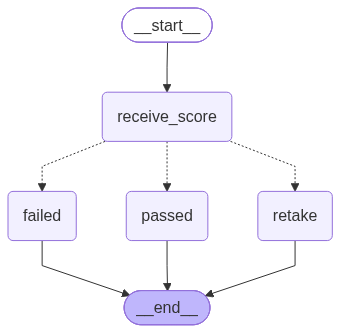

In [13]:
display(exam_graph)

In [14]:
for score in (95, 70, 30):
    print(f"\n🧑‍🎓 점수 {score}점")
    print("   결과:", exam_graph.invoke({"score": score})["message"])


🧑‍🎓 점수 95점
   ▶ 점수 접수: 95점
   ▶ 🎉 passed 노드
   결과: 합격입니다! 축하해요 🎉

🧑‍🎓 점수 70점
   ▶ 점수 접수: 70점
   ▶ 🔁 retake 노드
   결과: 재시험 대상입니다. 다음 주에 다시 도전하세요 🔁

🧑‍🎓 점수 30점
   ▶ 점수 접수: 30점
   ▶ 😢 failed 노드
   결과: 불합격입니다. 보충 학습을 추천해요 😢


**📝 정리** — 라우팅 함수의 반환값(노드 이름)에 따라 95점 → passed, 70점 → retake, 30점 → failed로 갔다. 라우팅 함수는 State를 읽기만 한다.

### 🗺️ `path_map` 으로 "라벨 → 노드" 연결하기

라우팅 함수가 **노드 이름이 아닌 라벨**(예: `"high"`)을 반환하게 하고 싶을 때는 `path_map` 딕셔너리로 연결합니다.
노드 이름을 바꿔도 라우팅 함수를 건드릴 필요가 없어 **유지보수에 유리**합니다.

In [15]:
def route_label(state: ExamState) -> str:
    return "high" if state["score"] >= 80 else "low"       # 노드 이름이 아닌 '라벨'

builder = StateGraph(ExamState)
builder.add_node("receive_score", receive_score)
builder.add_node("passed", passed)
builder.add_node("failed", failed)
builder.add_edge(START, "receive_score")
builder.add_conditional_edges(
    "receive_score",
    route_label,
    {"high": "passed", "low": "failed"},                    # 👈 라벨 → 실제 노드 매핑
)
builder.add_edge("passed", END)
builder.add_edge("failed", END)

label_graph = builder.compile()

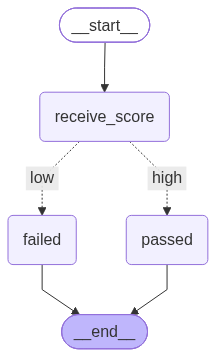

In [16]:
display(label_graph)

In [17]:
print(label_graph.invoke({"score": 85})["message"])
print(label_graph.invoke({"score": 50})["message"])

   ▶ 점수 접수: 85점
   ▶ 🎉 passed 노드
합격입니다! 축하해요 🎉
   ▶ 점수 접수: 50점
   ▶ 😢 failed 노드
불합격입니다. 보충 학습을 추천해요 😢


**📝 정리** — `path_map`으로 라벨(high/low)을 노드에 연결했다. 노드 이름이 바뀌어도 라우팅 함수는 그대로 둘 수 있다.

### ⚠️ 자주 하는 실수
- 라우팅 함수가 **등록되지 않은 노드 이름**을 반환하면 실행 중에 에러가 납니다. `Literal` 이나 `path_map` 으로 **가능한 목적지를 명시**하세요.
- 라우팅 함수 안에서 State 를 **수정하려고 하지 마세요** (반영되지 않습니다). 수정은 노드에서!

## 🌿 7장. 반복(사이클) — 그래프의 진짜 힘

### 📖 이론

조건부 엣지의 목적지를 **앞쪽 노드**로 설정하면 **루프(반복)** 가 됩니다.
**"결과가 만족스러울 때까지 다시 시도"** 하는 에이전트의 핵심 구조입니다.

```
          ┌────────────────────────────┐
          ▼                            │ (목표 미달)
 START ─▶ 💰 save_money ──▶ ❓ 목표 달성? ──┘
                                │ (달성)
                                ▼
                               END
```

#### 🛡️ 루프의 안전장치가 반드시 필요하다
- **종료 조건**이 영원히 만족되지 않으면 무한 반복됩니다.
- LangGraph 는 실행 단계(슈퍼스텝) 수에 **`recursion_limit`** 상한을 둡니다. 넘으면 **`GraphRecursionError`** 를 발생시킵니다.
- ⚠️ 학습/실험 중에는 `config={"recursion_limit": 10}` 처럼 **직접 작게** 지정해 두는 것이 안전합니다.
- LLM 을 부르는 루프는 **비용이 새지 않도록** 상태에 `반복 횟수` 카운터를 두고 직접 제한하는 것도 좋은 습관입니다. (20장)

In [18]:
class SavingState(TypedDict):
    balance: int       # 현재 저축액
    goal: int          # 목표 금액
    months: int        # 걸린 개월 수

def save_money(state: SavingState) -> dict:
    new_balance = state["balance"] + 300_000
    print(f"   ▶ {state['months'] + 1}개월차: {state['balance']:,}원 → {new_balance:,}원")
    return {"balance": new_balance, "months": state["months"] + 1}

# 🔀 반복 여부를 결정하는 라우팅 함수
def check_goal(state: SavingState) -> Literal["save_money", "__end__"]:
    return END if state["balance"] >= state["goal"] else "save_money"      # 미달이면 다시 save_money 로!

builder = StateGraph(SavingState)
builder.add_node("save_money", save_money)

builder.add_edge(START, "save_money")
builder.add_conditional_edges("save_money", check_goal)       # 자기 자신으로 되돌아가는 갈림길
saving_graph = builder.compile()

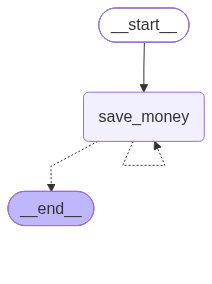

In [19]:
display(saving_graph)

In [20]:
result = saving_graph.invoke({"balance": 0, "goal": 1_000_000, "months": 0})
print(f"\n🎯 목표 달성! {result['months']}개월, 최종 {result['balance']:,}원")

   ▶ 1개월차: 0원 → 300,000원
   ▶ 2개월차: 300,000원 → 600,000원
   ▶ 3개월차: 600,000원 → 900,000원
   ▶ 4개월차: 900,000원 → 1,200,000원

🎯 목표 달성! 4개월, 최종 1,200,000원


**📝 정리** — 목표에 못 미치면 자기 자신(`save_money`)으로 돌아가는 루프. 4개월째 120만 원에서 END로 빠졌다.

### 🧪 무한 루프를 만들고 `recursion_limit` 으로 막아 보기

종료 조건이 **절대 만족되지 않는** 그래프를 만들고, 상한을 `6` 으로 낮춰 실행해 봅니다.

In [21]:
from langgraph.errors import GraphRecursionError

class LoopState(TypedDict):
    n: int

def tick(state: LoopState) -> dict:
    print(f"   ▶ tick {state['n']}")
    return {"n": state["n"] + 1}

builder = StateGraph(LoopState)
builder.add_node("tick", tick)

builder.add_edge(START, "tick")
builder.add_edge("tick", "tick")                 # ☠️ 자기 자신으로 무조건 이동 → 끝나지 않음
endless = builder.compile()

In [28]:
try:
    endless.invoke({"n": 0}, config={"recursion_limit": 6})        # 👈 상한을 직접 지정
except GraphRecursionError as e:
    print("\n🛑 GraphRecursionError 로 안전하게 중단됨")
    print("   ", str(e).splitlines()[0])

   ▶ tick 0
   ▶ tick 1
   ▶ tick 2
   ▶ tick 3
   ▶ tick 4
   ▶ tick 5

🛑 GraphRecursionError 로 안전하게 중단됨
    Recursion limit of 6 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


**📝 정리** — 종료 조건이 없는 그래프가 tick 0~5(6번)까지 돌고 `GraphRecursionError`로 멈췄다. 실험할 때는 `recursion_limit`을 작게 준다.

- `config={"recursion_limit": 6}` : 이 호출에서 **최대 6 슈퍼스텝**까지만 허용합니다.
- 에이전트가 도구를 계속 부르며 헤매는 상황(무한 루프)을 **비용·시간 폭탄이 되기 전에** 끊어 주는 안전망입니다.

`config는 LangGraph의 실행 엔진(Graph Executor / Pregel 엔진)에게 전달되는 전체 실행 제어 설정 객체입니다.`

- 엔진의 역할: 엔진은 그래프를 한 스텝씩 실행할 때마다 이 config에 담긴 옵션들을 확인합니다.
- config={"recursion_limit": 6}은 LangGraph의 내부 실행 엔진(Pregel)이 직접 가로채서 사용합니다.
   recursion_limit의 의미: "이 그래프가 무한 루프(Endless Loop)에 빠지더라도, 최대 6번의 슈퍼스텝(Super-step)까지만 돌고 강제로 멈춰라"라는 안전 장치(제한선)를 엔진에게 명령하는 것입니다. (기본값은 보통 25로 설정되어 있습니다.)

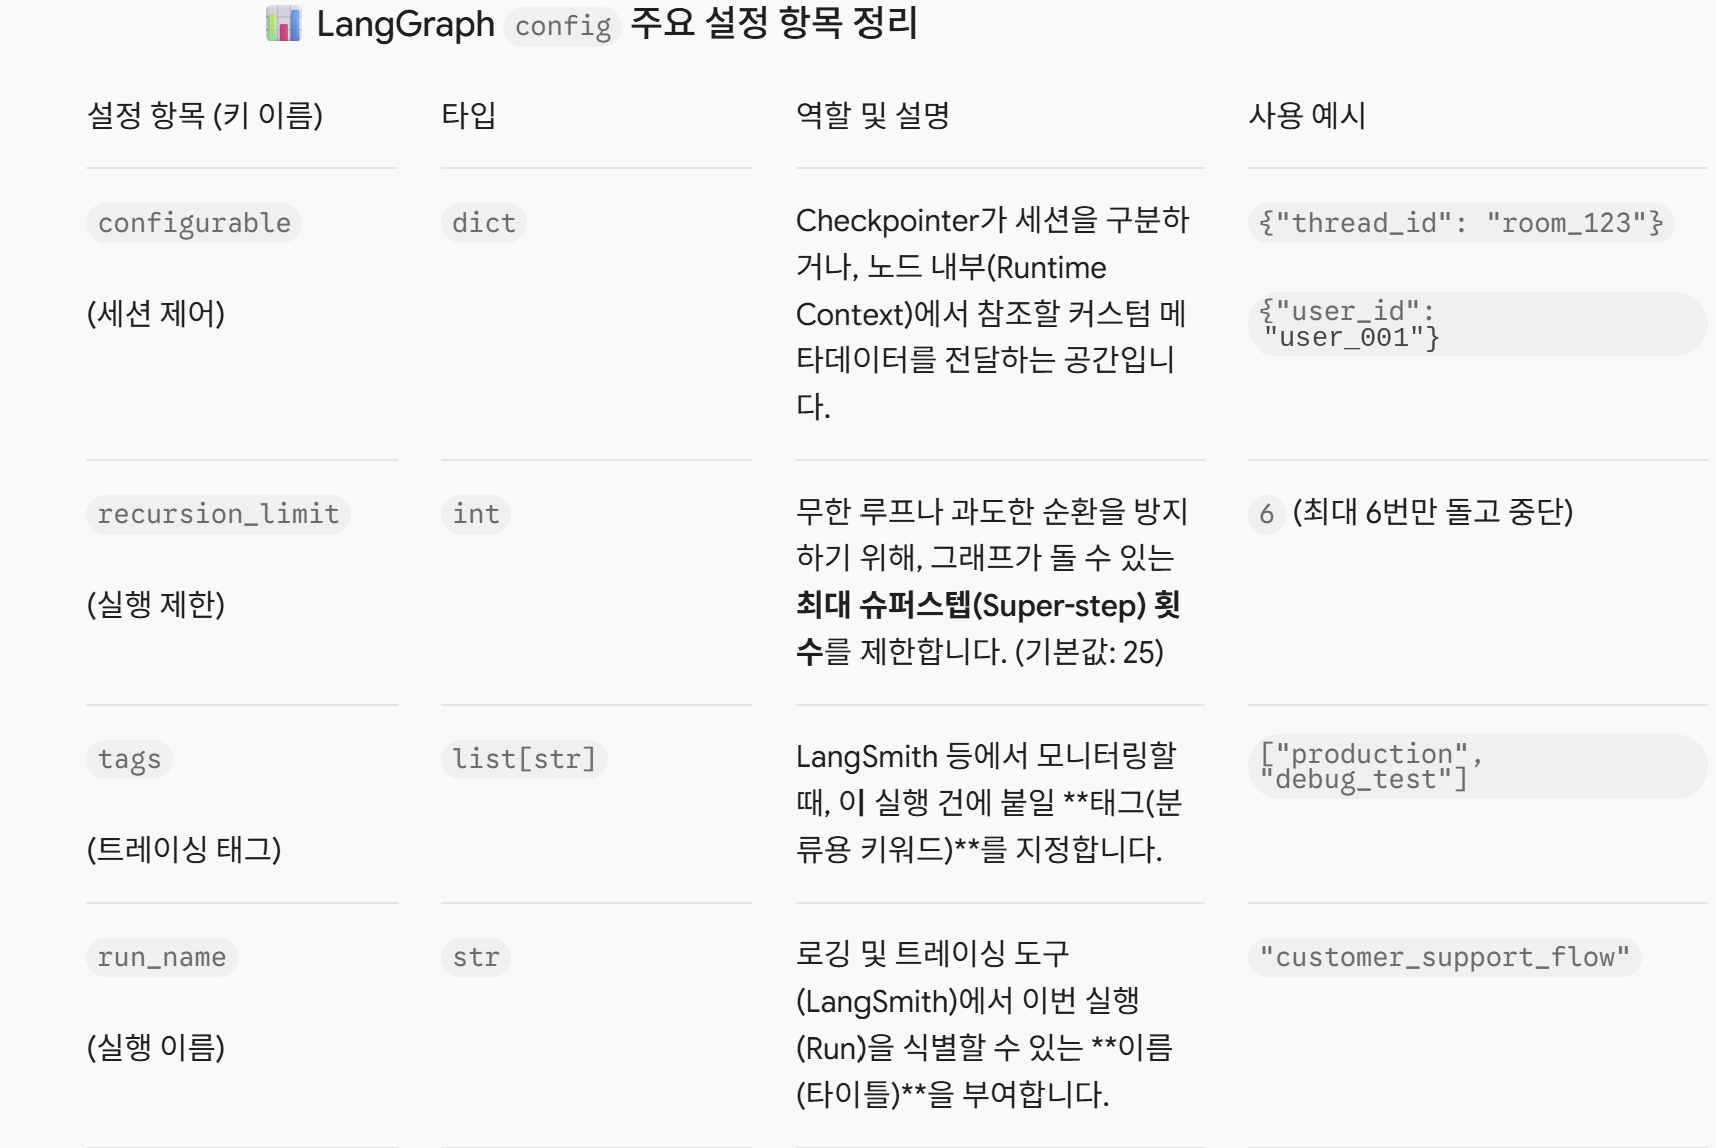

## 🌿 8장. 병렬 실행 — fan-out / fan-in

### 📖 이론

한 노드에서 **여러 노드로 동시에 뻗어 나가고(fan-out)**, 모두 끝나면 **한 노드로 모이는(fan-in)** 구조입니다.

```
                ┌──▶ 🔤 count_chars ──┐
 START ─────────┼──▶ 📝 count_words ──┼──▶ 📊 make_report ──▶ END
                └──▶ 😊 detect_mood ──┘
        (fan-out: 동시에 실행)            (fan-in: 모두 끝나야 실행)
```

#### 📌 꼭 알아야 할 규칙 3가지

| # | 규칙 | 설명 |
|:-:|------|------|
| 1 | **같은 슈퍼스텝의 노드는 병렬 실행** | 서로의 결과를 **볼 수 없음** (모두 같은 시점의 State 를 읽음) |
| 2 | **같은 필드에 동시에 쓰려면 리듀서 필수** | 없으면 `InvalidUpdateError` |
| 3 | **fan-in 은 `add_edge([A, B, C], "join")` (리스트)** | 리스트로 연결해야 **모두 끝날 때까지 기다림** |

<br>

> ⚠️ 규칙 3 이 특히 중요합니다. 분기마다 걸리는 단계 수가 다를 때, `add_edge("A","join")` 과 `add_edge("B","join")` 처럼 **따로** 연결하면 `join` 이 **여러 번** 실행될 수 있습니다. (아래에서 직접 확인)

In [23]:
import time

class ReviewState(TypedDict):
    review: str
    char_count: int
    word_count: int
    mood: str
    report: str
    log: Annotated[list[str], operator.add]       # 여러 노드가 같이 쓰는 필드 → 리듀서 필수!

def count_chars(state: ReviewState) -> dict:
    time.sleep(0.5)                                # 오래 걸리는 작업 흉내
    return {"char_count": len(state["review"]), "log": ["글자 수 계산 완료"]}

def count_words(state: ReviewState) -> dict:
    time.sleep(0.5)
    return {"word_count": len(state["review"].split()), "log": ["단어 수 계산 완료"]}

def detect_mood(state: ReviewState) -> dict:
    time.sleep(0.5)
    good = any(w in state["review"] for w in ("좋", "최고", "만족"))
    return {"mood": "긍정 😊" if good else "중립/부정 😐", "log": ["분위기 분석 완료"]}

def make_report(state: ReviewState) -> dict:
    return {
        "report": f"{state['char_count']}자 / {state['word_count']}단어 / 분위기: {state['mood']}",
        "log": ["리포트 작성 완료"],
    }

builder = StateGraph(ReviewState)
builder.add_node("count_chars", count_chars)
builder.add_node("count_words", count_words)
builder.add_node("detect_mood", detect_mood)
builder.add_node("make_report", make_report)

# fan-out: START 에서 3개 노드로 동시에
builder.add_edge(START, "count_chars")
builder.add_edge(START, "count_words")
builder.add_edge(START, "detect_mood")
# fan-in: 리스트로 연결 → 3개가 모두 끝나야 make_report 실행
builder.add_edge(["count_chars", "count_words", "detect_mood"], "make_report")
builder.add_edge("make_report", END)

parallel_graph = builder.compile()

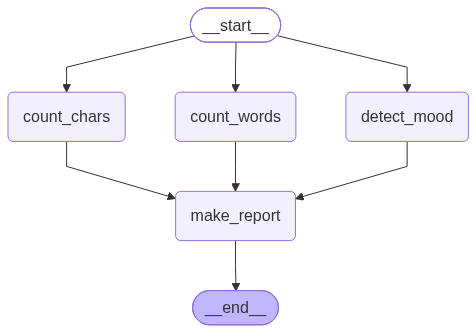

In [24]:
display(parallel_graph)

In [25]:

start = time.perf_counter()
result = parallel_graph.invoke({"review": "배송도 빠르고 품질이 최고예요 정말 만족합니다", "log": []})
elapsed = time.perf_counter() - start

print("📊", result["report"])
print("📜 로그:", result["log"])
print(f"⏱️ 걸린 시간: {elapsed:.2f}초  ← 0.5초 작업 3개가 순서대로면 1.5초, 병렬이라 약 0.5초!")

📊 25자 / 6단어 / 분위기: 긍정 😊
📜 로그: ['글자 수 계산 완료', '단어 수 계산 완료', '분위기 분석 완료', '리포트 작성 완료']
⏱️ 걸린 시간: 0.51초  ← 0.5초 작업 3개가 순서대로면 1.5초, 병렬이라 약 0.5초!


**📝 정리** — 0.5초짜리 노드 3개가 0.51초에 끝났다 → 진짜로 동시에 실행됐다. `log`는 `operator.add` 덕분에 세 노드의 기록이 모두 남았다.

- 3개 노드가 각각 `0.5초`씩 걸리는데 전체가 약 `0.5초` 만에 끝났다면 **진짜로 동시에 실행**된 것입니다.
- `log` 는 `operator.add` 리듀서 덕분에 **3개 노드의 로그가 모두 누적**됩니다. (리듀서가 없었다면 `InvalidUpdateError`)
- `make_report` 는 앞의 3개가 **모두 끝난 뒤**에야 실행되어 `char_count`, `word_count`, `mood` 를 모두 볼 수 있습니다.

### 🧪리듀서 없이 같은 필드에 동시에 쓰면?

In [29]:
from langgraph.errors import InvalidUpdateError

class NoReducerState(TypedDict):
    value: str                  # ❌ 리듀서 없음

def writer_a(state: NoReducerState) -> dict:
    return {"value": "A 가 씀"}

def writer_b(state: NoReducerState) -> dict:
    return {"value": "B 가 씀"}

builder = StateGraph(NoReducerState)
builder.add_node("writer_a", writer_a)
builder.add_node("writer_b", writer_b)
builder.add_edge(START, "writer_a")
builder.add_edge(START, "writer_b")
builder.add_edge("writer_a", END)
builder.add_edge("writer_b", END)

try:
    builder.compile().invoke({"value": ""})
except InvalidUpdateError as e:
    print("❌ InvalidUpdateError:", str(e).splitlines()[0])
    print("   → 같은 슈퍼스텝에서 두 노드가 같은 필드를 쓰면 '누구 값을 남길지' 알 수 없으므로 리듀서가 필요합니다")

❌ InvalidUpdateError: At key 'value': Can receive only one value per step. Use an Annotated key to handle multiple values.
   → 같은 슈퍼스텝에서 두 노드가 같은 필드를 쓰면 '누구 값을 남길지' 알 수 없으므로 리듀서가 필요합니다


**📝 정리** — 리듀서 없는 필드에 같은 슈퍼스텝의 두 노드가 쓰자 `InvalidUpdateError`(한 스텝에 값 하나만 받을 수 있음).

## 🌿 9장. `Send` : 개수가 정해지지 않은 병렬 처리 (Map-Reduce)

### 📖 이론

8장의 병렬은 **노드 개수가 미리 정해져** 있었습니다. 그런데 이런 경우는요?

> "도시 목록이 **몇 개가 들어올지 모르는데**, 각 도시의 날씨를 **하나씩 병렬로** 조회하고 싶다"

이때 `Send` 를 사용합니다. 라우팅 함수가 **`Send("노드이름", 그 노드에 넘길 입력)` 의 리스트**를 반환하면, 리스트 길이만큼 노드가 **병렬로 복제 실행**됩니다.

```
                         ┌─ Send("lookup", {"city":"서울"}) ─▶ 🔍 lookup ─┐
 📋 도시 목록 ──(Map)────┼─ Send("lookup", {"city":"부산"}) ─▶ 🔍 lookup ─┼─(Reduce)─▶ 📊 report
 (개수 가변!)            └─ Send("lookup", {"city":"제주"}) ─▶ 🔍 lookup ─┘
```

| 단계 | 하는 일 |
|------|---------|
| **Map** | 라우팅 함수가 항목마다 `Send` 를 만들어 반환 → 항목 수만큼 노드 병렬 실행 |
| **개별 처리** | 각 `lookup` 은 **자기에게 Send 된 입력**(`{"city": ...}`)만 받음 (전체 State 가 아님!) |
| **Reduce** | 결과를 **리듀서가 있는 필드**(`operator.add`)에 모아 담고, 다음 노드에서 집계 |

In [30]:
from langgraph.types import Send

FAKE_TEMPS = {"서울": 18, "부산": 21, "제주": 19, "대전": 17, "광주": 20}

class WeatherState(TypedDict):
    cities: list[str]                                 # 조회할 도시 목록 (개수 가변)
    temps: Annotated[list[tuple[str, int]], operator.add]   # Reduce: 결과 모으기
    report: str

# 🗺️ Map: 도시마다 Send 를 하나씩 만든다
def fan_out(state: WeatherState) -> list[Send]:
    return [Send("lookup", {"city": c}) for c in state["cities"]]

# 개별 처리: 이 노드는 Send 로 받은 {"city": ...} 만 입력으로 받는다
def lookup(payload: dict) -> dict:
    city = payload["city"]
    print(f"   ▶ {city} 조회 중…")
    return {"temps": [(city, FAKE_TEMPS.get(city, 0))]}

# 📊 Reduce 이후: 모인 결과를 집계
def report(state: WeatherState) -> dict:
    avg = sum(t for _, t in state["temps"]) / len(state["temps"])
    return {"report": f"{len(state['temps'])}개 도시 평균 기온: {avg:.1f}°C"}

builder = StateGraph(WeatherState)
builder.add_node("lookup", lookup)
builder.add_node("report", report)

builder.add_conditional_edges(START, fan_out, ["lookup"])     # START 에서 곧바로 Map
builder.add_edge("lookup", "report")
builder.add_edge("report", END)

send_graph = builder.compile()

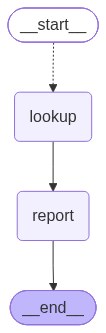

In [31]:
display(send_graph)

In [32]:
print("▶ 도시 3개")
print("  ", send_graph.invoke({"cities": ["서울", "부산", "제주"], "temps": []})["report"])
print("\n▶ 도시 5개 (같은 그래프, 개수만 다름!)")
print("  ", send_graph.invoke({"cities": ["서울", "부산", "제주", "대전", "광주"], "temps": []})["report"])

▶ 도시 3개
   ▶ 서울 조회 중…
   ▶ 부산 조회 중…
   ▶ 제주 조회 중…
   3개 도시 평균 기온: 19.3°C

▶ 도시 5개 (같은 그래프, 개수만 다름!)
   ▶ 서울 조회 중…
   ▶ 부산 조회 중…
   ▶ 제주 조회 중…
   ▶ 대전 조회 중…
   ▶ 광주 조회 중…
   5개 도시 평균 기온: 19.0°C


**📝 정리** — 같은 그래프인데 도시 수에 따라 `lookup`이 3번 / 5번 실행됐다. `lookup`은 State 전체가 아니라 `Send`로 받은 `{"city": ...}`만 받는다.

- `fan_out` 이 `Send` **리스트**를 반환하므로, 입력 도시 수에 따라 `lookup` 이 **3번 / 5번** 실행됩니다. 그래프 구조는 그대로인데 **병렬 개수는 동적**입니다.
- `lookup(payload)` 는 State 가 아니라 **`Send` 가 넘긴 딕셔너리**를 받습니다. (이 점이 일반 노드와 다릅니다)
- 결과는 `temps` (`operator.add`) 에 쌓이고, 모두 끝난 뒤 `report` 가 한 번 실행됩니다.
- 활용 예: 문서 여러 개를 각각 요약 후 합치기, 검색 쿼리 여러 개 동시 실행 등 **Map-Reduce 패턴 전부**.

## 🌿 10장. `Command` — 상태 업데이트 + 이동을 한 번에

### 📖 이론

지금까지는 **"노드는 상태만 바꾸고, 어디로 갈지는 엣지/라우팅 함수가 결정"** 했습니다.
그런데 **"검증을 해 본 노드 본인이 결과에 따라 다음 목적지까지 정하고 싶다"** 면 `Command` 를 반환하면 됩니다.

```python
return Command(
    update={"status": "검증 통과"},     # ① 상태를 이렇게 바꾸고
    goto="ship",                       # ② 다음엔 이 노드로 가라
)
```

| | 조건부 엣지 | `Command` |
|---|-------------|-----------|
| 상태 변경 | 노드가 반환 | `Command(update=...)` |
| 이동 결정 | **별도의 라우팅 함수** | 노드 **자신이** `goto` |
| 판단에 쓴 정보 | State 만 | 노드 안에서 계산한 중간 결과도 활용 |
| 그래프 그림 | 라우팅 함수의 `Literal` | **노드의 반환 타입** `Command[Literal[...]]` |
| 적합한 경우 | 단순 규칙 분기 | **"판단 + 갱신"이 한 덩어리**일 때 |

<br>

> 📌 `Command` 를 쓰는 노드에는 **반환 타입 힌트** `-> Command[Literal["a", "b"]]` 를 꼭 적으세요. 그래야 그래프 그림/컴파일이 갈 수 있는 목적지를 압니다.
> 🔮 `Command(resume=...)` 은 17장 Human-in-the-loop 에서 다시 만납니다.

In [33]:
from langgraph.types import Command

class OrderState(TypedDict):
    stock: int          # 재고
    qty: int            # 주문 수량
    status: str

# 🧠 검증 노드가 '상태 갱신 + 다음 목적지'를 한 번에 결정
def validate(state: OrderState) -> Command[Literal["ship", "reject"]]:
    if state["stock"] >= state["qty"]:
        print("   ▶ 재고 충분 → ship 으로")
        return Command(update={"status": "검증 통과 ✅"}, goto="ship")
    print("   ▶ 재고 부족 → reject 로")
    return Command(update={"status": f"재고 부족 ❌ (재고 {state['stock']} < 주문 {state['qty']})"}, goto="reject")

def ship(state: OrderState) -> dict:
    return {"status": state["status"] + " → 배송 시작 🚚"}

def reject(state: OrderState) -> dict:
    return {"status": state["status"] + " → 주문 취소 🙅"}

builder = StateGraph(OrderState)
builder.add_node("validate", validate)
builder.add_node("ship", ship)
builder.add_node("reject", reject)

builder.add_edge(START, "validate")
builder.add_edge("ship", END)
builder.add_edge("reject", END)
# ※ validate → ship/reject 엣지는 add_edge 로 연결하지 않았다! Command(goto=...) 가 대신함
order_graph = builder.compile()

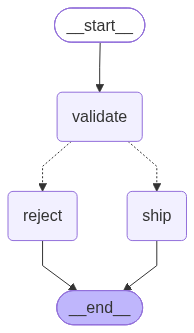

In [34]:
display(order_graph)

In [35]:
print("▶ 주문 3개 / 재고 10개")
print("  ", order_graph.invoke({"stock": 10, "qty": 3, "status": ""})["status"])
print("▶ 주문 30개 / 재고 10개")
print("  ", order_graph.invoke({"stock": 10, "qty": 30, "status": ""})["status"])

▶ 주문 3개 / 재고 10개
   ▶ 재고 충분 → ship 으로
   검증 통과 ✅ → 배송 시작 🚚
▶ 주문 30개 / 재고 10개
   ▶ 재고 부족 → reject 로
   재고 부족 ❌ (재고 10 < 주문 30) → 주문 취소 🙅


**📝 정리** — 엣지를 그리지 않았는데 `Command(goto=...)`로 ship/reject로 이동했다. 그림에 선이 나온 것은 반환 타입 힌트 `Command[Literal[...]]` 덕분이다.

- `validate` 에서 `ship` / `reject` 로 가는 **엣지를 직접 그리지 않았는데도** 그림에 연결선이 나타납니다. `Command[Literal["ship","reject"]]` 타입 힌트를 보고 그렸기 때문입니다.
- 한 노드가 **"판단 → 상태 기록 → 이동"** 을 모두 하므로 코드가 한곳에 모여 읽기 쉽습니다.
- **어느 쪽을 쓸까?** 규칙이 단순하면 조건부 엣지(분기 로직이 노드와 분리됨), 노드 안에서만 알 수 있는 정보로 판단하거나 상태 갱신과 이동이 한 덩어리면 `Command`.

## 🌿 11장. 런타임 컨텍스트 — `context_schema`

### 📖 이론

그래프를 실행할 때 **"흐르는 데이터"가 아닌 "실행 환경 설정"** 을 넘기고 싶을 때가 있습니다.
예) 사용자 이름, 언어, 사용할 모델 이름, DB 연결 …

| | **State** | **Context** (런타임 컨텍스트) |
|---|-----------|-------------------------------|
| 성격 | 노드를 거치며 **계속 바뀌는** 데이터 | 실행 내내 **변하지 않는** 설정 |
| 선언 | `StateGraph(State)` | `StateGraph(State, context_schema=Ctx)` |
| 전달 | `invoke({...})` 의 입력 | `invoke(..., context=Ctx(...))` |
| 노드에서 | `state["x"]` | `runtime.context.x` |
| 체크포인트에 저장 | ✅ | ❌ (실행마다 새로 주입) |

```python
def node(state: State, runtime: Runtime[Ctx]):      # 👈 두 번째 인자로 runtime 을 받으면 자동 주입
    lang = runtime.context.lang
```

> 💡 "이 값은 노드가 바꾸지 않는다 / 대화에 저장될 필요 없다" 싶으면 Context, "흐르면서 바뀐다" 싶으면 State.

In [36]:
from dataclasses import dataclass
from langgraph.runtime import Runtime

# 🌐 실행 환경 설정(불변): 사용자 이름과 언어
@dataclass
class AppContext:
    user_name: str
    lang: str = "ko"

class HelloState(TypedDict):
    message: str

def say_hello(state: HelloState, runtime: Runtime[AppContext]) -> dict:
    ctx = runtime.context                                  # 👈 실행 시 주입된 컨텍스트
    text = f"안녕하세요, {ctx.user_name}님!" if ctx.lang == "ko" else f"Hello, {ctx.user_name}!"
    return {"message": text}

builder = StateGraph(HelloState, context_schema=AppContext)      # 👈 컨텍스트 스키마 선언
builder.add_node("say_hello", say_hello)

builder.add_edge(START, "say_hello")
builder.add_edge("say_hello", END)
hello_graph = builder.compile()

In [37]:

# 같은 그래프를 컨텍스트만 바꿔 재사용
print(hello_graph.invoke({"message": ""}, context=AppContext(user_name="둘리", lang="ko"))["message"])
print(hello_graph.invoke({"message": ""}, context=AppContext(user_name="unico", lang="en"))["message"])

안녕하세요, 둘리님!
Hello, unico!


**📝 정리** — 같은 그래프를 `context`만 바꿔 한국어/영어로 인사했다. Context는 체크포인트에 저장되지 않는 실행 설정이다.

- 노드 함수의 **두 번째 파라미터** `runtime: Runtime[AppContext]` 를 선언하기만 하면 LangGraph 엔진이 알아서 넣어 줍니다.
- 같은 그래프 객체로 **사용자·언어만 바꿔** 여러 번 호출할 수 있어, **멀티 유저 서비스**에서 특히 유용합니다.
- 실무 예: `context` 에 `user_id`, `db`, `model_name` 을 담아 노드에서 꺼내 쓰기.


---
### 🎉 여기까지가 "LLM 없이 배우는 LangGraph 문법"입니다!

![LangGraph 핵심 구조와 실행 흐름_exam9.png](<attachment:LangGraph 핵심 구조와 실행 흐름_exam9.png>)
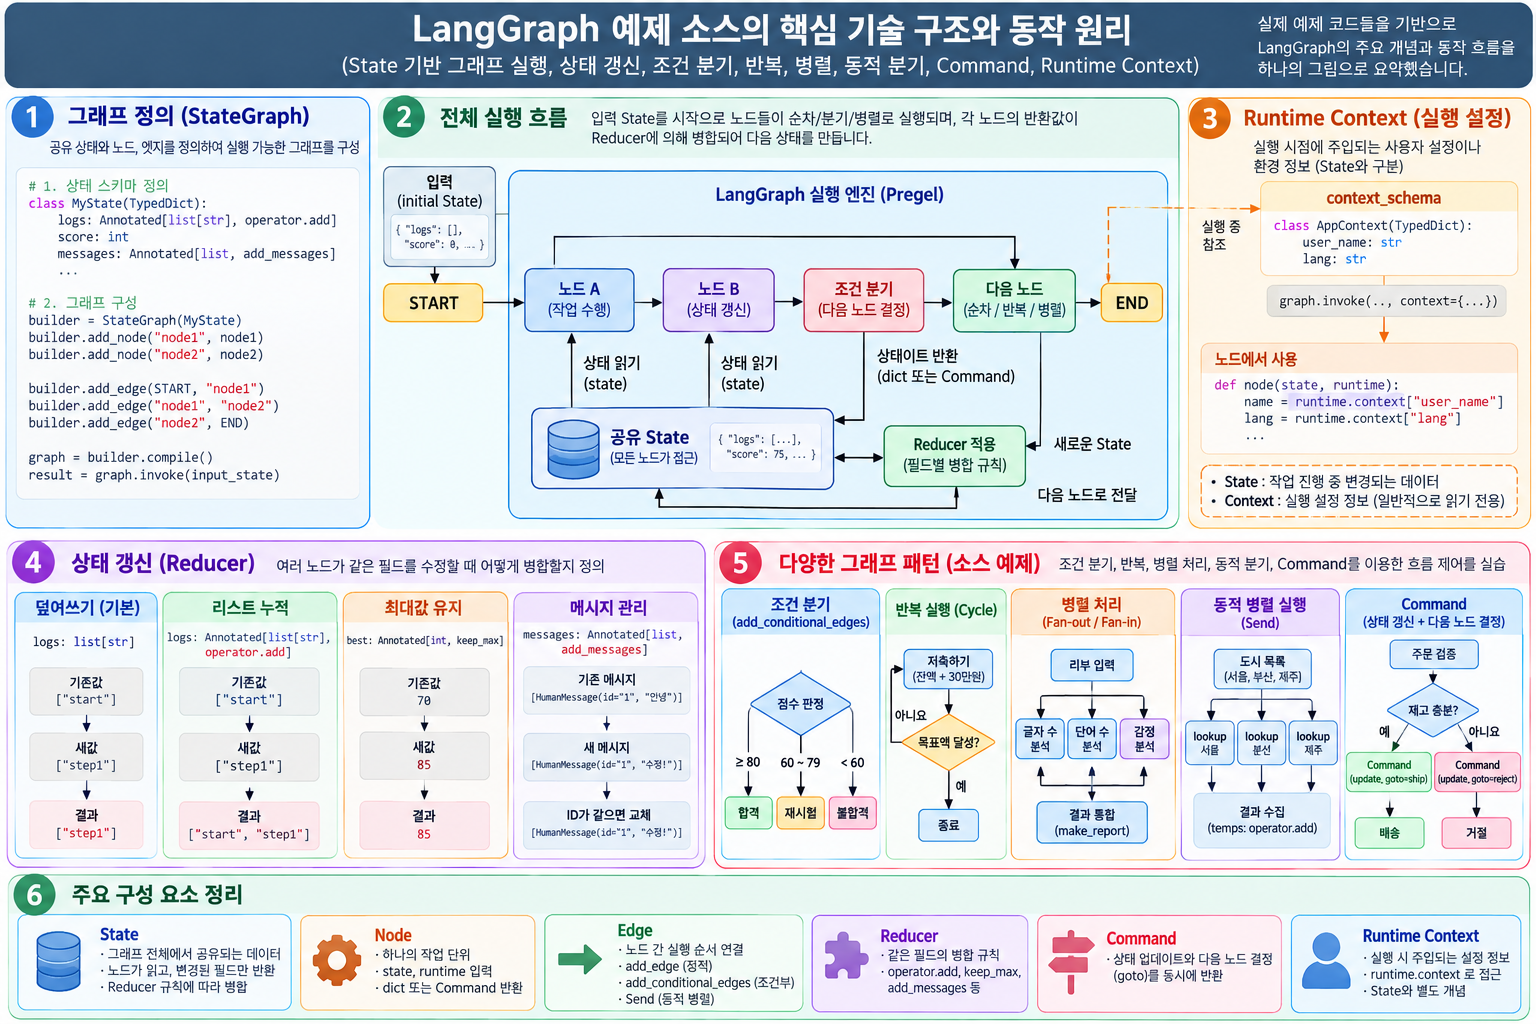

## 🔁 복습 질문

<details>
<summary>1. 리듀서를 지정하는 문법은?</summary>

`필드: Annotated[타입, 리듀서함수]` (예: `Annotated[list[str], operator.add]`).
</details>

<details>
<summary>2. fan-in에서 <code>add_edge([A, B, C], "join")</code>처럼 리스트로 연결하는 이유는?</summary>

A, B, C가 모두 끝난 뒤에 join이 한 번만 실행되게 하려고.
</details>

<details>
<summary>3. <code>Send</code>로 실행되는 노드가 받는 입력은?</summary>

State 전체가 아니라 `Send("노드", 입력)`에 넣은 dict.
</details>

<details>
<summary>4. 조건부 엣지와 <code>Command</code> 중 무엇을 쓸까?</summary>

단순 규칙 분기는 조건부 엣지, 노드 안에서 계산한 결과로 판단하고 상태 갱신과 이동이 한 덩어리면 Command.
</details>
